# M5 Forecasting Accuracy: EDA

**Contents**
1. Import libraries
2. Load sales data and choose dtypes
3. Sales data: structure and reshape
   - 3.1 Structure
   - 3.2 Melt into long format
4. Calendar: events and SNAP days
   - 4.1 Events
   - 4.2 Join sales with calendar
   - 4.3 SNAP days
5. Sell prices: price changes and their effect on sales
   - 5.1 Price changes
   - 5.2 Join sales with prices and drop rows before launch
   - 5.3 Sales around price changes
6. Sales patterns
   - 6.1 Trend
   - 6.2 Day of week and month
   - 6.3 Events
   - 6.4 SNAP effect
   - 6.5 Zero sales
   - 6.6 Sales history
   - 6.7 Trend and yearly seasonality (decomposition)
   - 6.8 Recent trend vs the forecast window
7. Feature summary

## Validation strategy
- ใช้ข้อมูลจาก `sales_train_evaluation.csv` ทั้งหมด แบ่งตามวัน
- แบ่งตามลำดับเวลาเสมอ โมเดลไม่เห็นวันที่อยู่หลังช่วงที่กำลังพยากรณ์ เพื่อป้องกัน data leakage
- ไม่สุ่มแบ่งวัน

| Period | Days | Role |
|---|---|---|
| Training | `d_1` – `d_1913` | ใช้ fit โมเดลระหว่างพัฒนา |
| Validation | `d_1914` – `d_1941` | วัด WRMSSE กับยอดขายที่รู้คำตอบแล้ว |
| Evaluation | `d_1942` – `d_1969` | พยากรณ์จริง (ไม่รู้ยอดขาย) |

ทำงานเป็น 2 ขั้น:

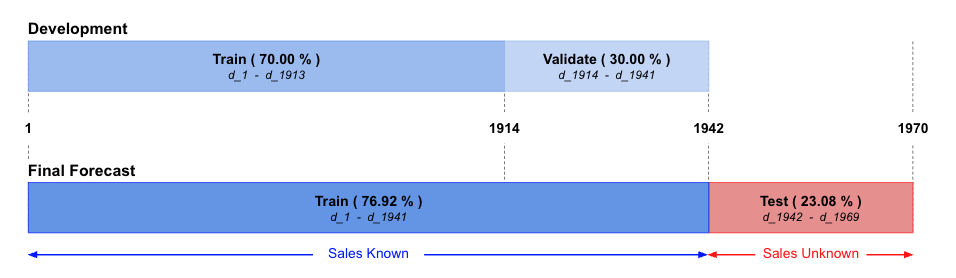

1. **Development**
   - train ด้วย `d_1` – `d_1913` แล้วพยากรณ์ `d_1914` – `d_1941`
   - เทียบผลพยากรณ์กับยอดขายจริงเพื่อคำนวณ `WRMSSE`
   - ใช้คะแนนนี้ตัดสินว่าการเปลี่ยน feature หรือ parameter ดีขึ้นหรือไม่
2. **Final forecast**
   - train ใหม่ด้วยข้อมูลทั้งหมดถึง `d_1941` ด้วยการตั้งค่าที่เลือกไว้ แล้วพยากรณ์ `d_1942` – `d_1969`
   - 28 วันล่าสุดใกล้ช่วงพยากรณ์ที่สุด จึงใส่ไว้ใน train รอบสุดท้ายด้วย

ก่อน train รวมทุกตารางเป็น 1 แถวต่อสินค้า ร้าน และวัน:

- `sales_train_evaluation.csv` เปลี่ยนจากแนวกว้างเป็นแนวยาว (1 คอลัมน์ต่อวัน → 1 แถวต่อวัน)
- join `calendar.csv` ด้วย `d`
- join `sell_prices.csv` ด้วย `store_id`, `item_id` และ `wm_yr_wk`
  แล้วตัดแถวที่ไม่มีราคา เพราะสินค้ายังไม่วางขาย

**สิ่งที่ปรับปรุงได้:** validation ช่วงเดียว 28 วันอาจตกช่วงที่ผิดปกติ
ถ้าทำ walk-forward validation หลายช่วง (เช่น สิ้นสุดที่ `d_1885`, `d_1913` และ `d_1941`) จะได้ค่าที่น่าเชื่อถือกว่า

## โหลดและ melt ยอดขาย
**ภาพรวม:** ยอดขายมาเป็นตารางแนวกว้าง 30,490 แถว (3,049 สินค้า × 10 ร้าน) แต่ละวันเป็น 1 คอลัมน์ รวม 1,941 วัน

**ปัญหา:** โมเดลต้องการ 1 แถวต่อ 1 วัน จึงจะใส่ข้อมูลของวันนั้นได้ เช่น วันในสัปดาห์ event และราคา
พอ melt แล้วจะได้ 59.2 ล้านแถว ถ้าใช้ dtype แบบ default จะใช้ RAM 4.6 GB ก่อนจะ join อีก 2 ตารางด้วยซ้ำ

**ดูเพิ่ม:**
- ช่วงค่าของแต่ละคอลัมน์ (เช่น ยอดขายสูงสุดต่อวัน 763) เพื่อเลือก dtype ที่เล็กที่สุดแต่ยังพอ
- จำนวนแถวต่อวัน: ทุกวันมีครบ 30,490 แถว รวมถึงวันที่สินค้ายังไม่วางขายด้วย

**Action:**
- กำหนด dtype ตั้งแต่ตอนโหลด ตารางหลัง melt ใช้ RAM 0.7 GB
- ใช้ `day` ที่เป็นตัวเลขแทน `d` ที่เป็นข้อความ
- แถวก่อนสินค้าวางขายยังไม่ตัดตอนนี้ แต่ตัดตอน join ราคาใน 5.2

### 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots
from statsmodels.tsa.seasonal import MSTL

pio.templates.default = "plotly_white"

# สีประจำหมวดสินค้า ใช้ชุดเดียวกันทุกกราฟ
CAT_COLORS = {"FOODS": "#2a78d6", "HOBBIES": "#eb6834", "HOUSEHOLD": "#1baf7a"}
# กราฟที่ไม่ได้แยกตามหมวดใช้สีกลาง เพื่อไม่ให้สับสนกับสีของหมวด
NEUTRAL = "#660099"
NEUTRAL_LIGHT = "#c9a6db"  # สีเดียวกันแบบอ่อน ใช้คู่กับ NEUTRAL เมื่อต้องการเน้นบางแท่ง
LINE_COLOR = "#222222"     # กราฟเส้นที่ไม่ได้แยกตามหมวด

### 2. Load sales data and choose dtypes
ตารางนี้จะถูก melt เป็นราว 59 ล้านแถว แล้ว join กับอีก 2 ตาราง จึงเลือก dtype ตั้งแต่ตอนโหลด
ถ้ารอลดขนาดหลัง join ตารางขนาดเต็มจะถูกสร้างไปแล้วตอน melt และ join ซึ่งเป็นช่วงที่ใช้ RAM สูงสุด
ส่วน `calendar.csv` (1,969 แถว) และ `sell_prices.csv` (6.8 ล้านแถว) เล็กกว่ามาก ลดขนาดก่อน join ก็พอ

| คอลัมน์ | ช่วงค่าในข้อมูล | dtype | ไฟล์ |
|---|---|---|---|
| `d_1` – `d_1941` → `sales` | 0 – 763 | `int16` | sales |
| `day` | 1 – 1,969 | `int16` | sales, calendar |
| `wm_yr_wk` | 11101 – 11621 | `int16` | calendar, prices |
| `year` | 2011 – 2016 | `int16` | calendar |
| `wday`, `month`, `snap_*` | 0 – 12 | `int8` | calendar |
| `sell_price` | 0.01 – 107.32 | `float32` | prices |
| `id`, `item_id`, `dept_id`, `cat_id`, `store_id`, `state_id`, `event_*` | ข้อความที่ซ้ำกันมาก | `category` | ทุกไฟล์ |

- `int16` เก็บได้ถึง 32,767 และ `int8` ถึง 127 จึงพอสำหรับทุกคอลัมน์ข้างบน
- `float32` แม่นยำราว 7 หลัก พอสำหรับราคาที่มีทศนิยม 2 ตำแหน่ง
- ผลรวมของ `int16` ไม่ล้น เพราะ pandas คืน `groupby().sum()` และ `cumsum()` เป็น `int64`

In [2]:
id_cols = ["id", "item_id", "dept_id", "cat_id", "store_id", "state_id"]
d_cols = [f"d_{i}" for i in range(1, 1942)]

sales_df = pd.read_csv("m5-data/sales_train_evaluation.csv", dtype=dict.fromkeys(d_cols, "int16"))
# แปลงเป็น category หลังโหลด เพื่อให้ categories เรียงตามตัวอักษร
sales_df[id_cols] = sales_df[id_cols].astype("category")
print(f"Max daily sales: {sales_df[d_cols].max().max()}")
sales_df.head()

Max daily sales: 763


,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4,...,d_1932,d_1933,d_1934,d_1935,d_1936,d_1937,d_1938,d_1939,d_1940,d_1941
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,2,4,0,0,0,0,3,3,0,1
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,0,1,2,1,1,0,0,0,0,0
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,0,2,0,0,0,2,3,0,1
3,HOBBIES_1_004_CA_1_evaluation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,1,0,4,0,1,3,0,2,6
4,HOBBIES_1_005_CA_1_evaluation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,0,0,0,2,1,0,0,2,1,0


### 3. Sales data: structure and reshape

#### 3.1 Structure: 30,490 rows × 1,947 columns
- 1 แถว = สินค้า 1 รายการใน 1 ร้าน (3,049 items × 10 stores = 30,490)
- 6 คอลัมน์แรกเป็น ID: `id`, `item_id`, `dept_id`, `cat_id`, `store_id`, `state_id`
- `d_1` – `d_1941` คือยอดขายรายวัน รวม 1,941 คอลัมน์

In [3]:
sales_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30490 entries, 0 to 30489
Columns: 1947 entries, id to d_1941
dtypes: category(6), int16(1941)
memory usage: 113.4 MB


#### 3.2 Melt `d_1` – `d_1941` into long format
- `day` เป็นตัวเลขของวัน (`d_1` → 1) ใช้เรียงลำดับเวลาและ join กับ `calendar.csv`
- ไม่เก็บ `d` ที่เป็นข้อความ เพราะข้อความ 59 ล้านแถวใช้ RAM ราว 3 GB จากทั้งหมด 4.6 GB

In [4]:
# เปลี่ยนชื่อคอลัมน์ d_1 → 1 ก่อน melt จะได้ day เป็นตัวเลขตั้งแต่แรก ไม่ต้องสร้างคอลัมน์ข้อความ
sales_df.columns = id_cols + [int(c[2:]) for c in d_cols]

long_df = sales_df.melt(id_vars=id_cols, var_name="day", value_name="sales")
long_df["day"] = long_df["day"].astype("int16")
long_df.head()

,id,item_id,dept_id,cat_id,store_id,state_id,day,sales
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,1,0
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,1,0
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,1,0
3,HOBBIES_1_004_CA_1_evaluation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,1,0
4,HOBBIES_1_005_CA_1_evaluation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,1,0


In [5]:
long_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 59181090 entries, 0 to 59181089
Data columns (total 8 columns):
 #   Column    Dtype   
---  ------    -----   
 0   id        category
 1   item_id   category
 2   dept_id   category
 3   cat_id    category
 4   store_id  category
 5   state_id  category
 6   day       int16   
 7   sales     int16   
dtypes: category(6), int16(2)
memory usage: 677.5 MB


In [6]:
long_df.describe()

,day,sales
count,5.918109e+07,5.918109e+07
mean,9.710000e+02,1.130888e+00
std,5.603184e+02,3.870038e+00
min,1.000000e+00,0.000000e+00
25%,4.860000e+02,0.000000e+00
50%,9.710000e+02,0.000000e+00
75%,1.456000e+03,1.000000e+00
max,1.941000e+03,7.630000e+02


ทุกวันมี 30,490 แถวเท่ากัน แปลว่าสินค้าทุกรายการมีแถวครบทุกวัน
รวมถึงช่วงก่อนเริ่มวางขาย ซึ่งยอดขายเป็น 0 แถวเหล่านี้จะถูกตัดออกตอน join กับ `sell_prices.csv` (ดู 5.2)

In [7]:
long_df.groupby("day").size().agg(["min", "max"])

min    30490
max    30490
dtype: int64

## ปฏิทิน
**ภาพรวม:** `calendar.csv` มี 1 แถวต่อวัน บอก event 2 คอลัมน์ (`event_name_1`, `event_name_2`) และวัน SNAP แยก 3 คอลัมน์ตามรัฐ

**ปัญหา:**
- `event_name_2` แทบว่างทั้งคอลัมน์ ไม่แน่ใจว่ามีข้อมูลที่ `event_name_1` ไม่มีหรือไม่
- SNAP มี 3 คอลัมน์ แต่แต่ละร้านอยู่ในรัฐเดียว อีก 2 คอลัมน์จึงไม่เกี่ยวกับร้านนั้น

**ดูเพิ่ม:**
- `event_name_2` มีแค่ 5 วัน และ event ทุกรายการในนั้นมีอยู่ใน `event_name_1` ของปีอื่นแล้ว (4.1)
- วัน SNAP ตกวันที่เดิมทุกเดือน เดือนละ 10 วัน (4.3) จึงรู้ล่วงหน้าว่าวันในช่วงพยากรณ์เป็น SNAP หรือไม่

**Action:**
- ตัด `event_name_2` เพราะโมเดลยังเรียนผลของ event เหล่านั้นจาก `event_name_1` ได้
- รวม SNAP เป็นคอลัมน์ `snap` เดียว โดยใช้ค่าของรัฐที่ร้านตั้งอยู่ แล้วใช้เป็น feature

### 4. Calendar: events and SNAP days

In [8]:
calendar_df = pd.read_csv("m5-data/calendar.csv", parse_dates=["date"])
calendar_df.head()

,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI
0,2011-01-29,11101,Saturday,1,1,2011,d_1,NaN,NaN,NaN,NaN,0,0,0
1,2011-01-30,11101,Sunday,2,1,2011,d_2,NaN,NaN,NaN,NaN,0,0,0
2,2011-01-31,11101,Monday,3,1,2011,d_3,NaN,NaN,NaN,NaN,0,0,0
3,2011-02-01,11101,Tuesday,4,2,2011,d_4,NaN,NaN,NaN,NaN,1,1,0
4,2011-02-02,11101,Wednesday,5,2,2011,d_5,NaN,NaN,NaN,NaN,1,0,1


In [9]:
calendar_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1969 entries, 0 to 1968
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   date          1969 non-null   datetime64[us]
 1   wm_yr_wk      1969 non-null   int64         
 2   weekday       1969 non-null   str           
 3   wday          1969 non-null   int64         
 4   month         1969 non-null   int64         
 5   year          1969 non-null   int64         
 6   d             1969 non-null   str           
 7   event_name_1  162 non-null    str           
 8   event_type_1  162 non-null    str           
 9   event_name_2  5 non-null      str           
 10  event_type_2  5 non-null      str           
 11  snap_CA       1969 non-null   int64         
 12  snap_TX       1969 non-null   int64         
 13  snap_WI       1969 non-null   int64         
dtypes: datetime64[us](1), int64(7), str(6)
memory usage: 215.5 KB


#### 4.1 Events: drop `event_name_2`
**สมมติฐาน:** `event_name_2` มีข้อมูลน้อยและซ้ำกับ `event_name_1` จึงตัดออกได้โดยไม่เสียข้อมูล

**สรุป:** ตัดออกได้ เพราะ
- มีข้อมูลเพียง 5 วัน จากทั้งหมด 1,969 วัน (ราว 0.25%)
  ซึ่งเป็นวันที่มี event สองรายการตรงกันโดยบังเอิญ
- event ทุกรายการใน `event_name_2` ปรากฏใน `event_name_1` ในปีอื่นอยู่แล้ว
  โมเดลจึงยังเรียนรู้ผลของ event เหล่านั้นได้จาก `event_name_1`
- ข้อมูลที่มีเพียงไม่กี่วัน ไม่พอให้โมเดลเรียนรู้รูปแบบได้อย่างน่าเชื่อถือ
  และยังเพิ่มคอลัมน์ที่ต้องใช้ RAM ในตารางราว 59 ล้านแถว

**Action:** ตัด `event_name_2` และ `event_type_2` ใช้ `event_name_1` คอลัมน์เดียว

In [10]:
event_counts = (
    calendar_df[["event_name_1", "event_name_2"]]
    .melt(var_name="column", value_name="event")
    .dropna()
    .groupby(["event", "column"], observed=True)
    .size()
    .reset_index(name="days")
)

order = event_counts.groupby("event")["days"].sum().sort_values().index.tolist()

fig = px.bar(
    event_counts,
    x="days", y="event", color="column",
    orientation="h", color_discrete_map={"event_name_1": NEUTRAL, "event_name_2": NEUTRAL_LIGHT},
    category_orders={"event": order},
    title="Event days by column",
    labels={"days": "Number of days", "event": "", "column": ""},
    height=800,
)
fig.show()

In [11]:
n = calendar_df["event_name_2"].notna().sum()
print(f"Days with event_name_2: {n} ({n / len(calendar_df):.2%})")

# อีเวนต์ใน event_name_2 ที่ไม่เคยอยู่ใน event_name_1 (set ว่าง = ไม่มี)
set(calendar_df["event_name_2"].dropna()) - set(calendar_df["event_name_1"].dropna())

Days with event_name_2: 5 (0.25%)


set()

In [12]:
calendar_df["day"] = calendar_df["d"].str[2:].astype("int16")
calendar_df = calendar_df[[
    "day", "date", "wm_yr_wk", "wday", "month", "year",
    "event_name_1", "event_type_1", "snap_CA", "snap_TX", "snap_WI",
]]

# ลดขนาด dtype ก่อน join กับตาราง 59 ล้านแถว (ดูตารางใน 2.)
for c in ["event_name_1", "event_type_1"]:
    calendar_df[c] = calendar_df[c].astype("category")
for c in ["wday", "month", "snap_CA", "snap_TX", "snap_WI"]:
    calendar_df[c] = calendar_df[c].astype("int8")
for c in ["wm_yr_wk", "year"]:
    calendar_df[c] = calendar_df[c].astype("int16")
calendar_df.head()

,day,date,wm_yr_wk,wday,month,year,event_name_1,event_type_1,snap_CA,snap_TX,snap_WI
0,1,2011-01-29,11101,1,1,2011,NaN,NaN,0,0,0
1,2,2011-01-30,11101,2,1,2011,NaN,NaN,0,0,0
2,3,2011-01-31,11101,3,1,2011,NaN,NaN,0,0,0
3,4,2011-02-01,11101,4,2,2011,NaN,NaN,1,1,0
4,5,2011-02-02,11101,5,2,2011,NaN,NaN,1,0,1


#### 4.2 Join sales with calendar
- `calendar.csv` มี 1 แถวต่อวัน จึงเป็นการ join แบบ many-to-one จำนวนแถวต้องเท่าเดิม
- join ด้วย `day` ที่เป็น `int16` แทน `d` ที่เป็นข้อความ

In [13]:
merge_df = long_df.merge(calendar_df, on="day", how="left", validate="many_to_one")
assert len(merge_df) == len(long_df)

# คืน RAM: ไม่ต้องใช้ตารางก่อน join แล้ว
del sales_df, long_df
merge_df.head()

,id,item_id,dept_id,cat_id,store_id,state_id,day,sales,date,wm_yr_wk,wday,month,year,event_name_1,event_type_1,snap_CA,snap_TX,snap_WI
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,1,0,2011-01-29,11101,1,1,2011,NaN,NaN,0,0,0
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,1,0,2011-01-29,11101,1,1,2011,NaN,NaN,0,0,0
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,1,0,2011-01-29,11101,1,1,2011,NaN,NaN,0,0,0
3,HOBBIES_1_004_CA_1_evaluation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,1,0,2011-01-29,11101,1,1,2011,NaN,NaN,0,0,0
4,HOBBIES_1_005_CA_1_evaluation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,1,0,2011-01-29,11101,1,1,2011,NaN,NaN,0,0,0


#### 4.3 SNAP days
**สมมติฐาน:** แต่ละรัฐมีวัน SNAP ตายตัวทุกเดือน และร้านได้รับผลเฉพาะ SNAP ของรัฐตัวเอง
จึงรวมเป็นคอลัมน์ `snap` เดียวตามรัฐของร้านได้ และรู้ล่วงหน้าว่าวันในช่วงที่ต้องพยากรณ์เป็น SNAP หรือไม่

**สรุป:** ทุกรัฐมี SNAP 10 วันต่อเดือน ตกวันที่เดิมทุกเดือน และอยู่ในครึ่งแรกของเดือนทั้งหมด
(CA วันที่ 1–10, TX และ WI กระจายในวันที่ 1–15)

**Action:** รวม 3 คอลัมน์เป็น `snap` คอลัมน์เดียว โดยใช้ค่าของรัฐที่ร้านตั้งอยู่ แล้วใช้เป็น feature

- SNAP ย่อมาจาก Supplemental Nutrition Assistance Program
- คือวันที่รัฐบาลสหรัฐฯ จ่ายเงินช่วยเหลือค่าอาหารให้ครอบครัวรายได้น้อย

In [14]:
snap_cols = ["snap_CA", "snap_TX", "snap_WI"]
snap_by_dom = (
    calendar_df.assign(day_of_month=calendar_df["date"].dt.day)
    .groupby("day_of_month")[snap_cols].mean()
    .T.rename(index=lambda c: c.replace("snap_", ""))
)

fig = go.Figure(go.Heatmap(
    z=snap_by_dom.values, x=snap_by_dom.columns, y=snap_by_dom.index,
    colorscale=[[0, "#f0efec"], [1, NEUTRAL]], showscale=False,
    xgap=2, ygap=2,
    hovertemplate="%{y}, day %{x}: %{z:.0%} SNAP<extra></extra>",
))
fig.update_xaxes(dtick=1, title="Day of month", showgrid=False)
fig.update_yaxes(title=None, autorange="reversed", showgrid=False)
fig.update_layout(
    title="SNAP days by state (purple = SNAP day)",
    height=260,
)
fig.show()

รวม `snap_CA`, `snap_TX`, `snap_WI` เป็น `snap` คอลัมน์เดียว โดยใช้ค่าของรัฐที่ร้านตั้งอยู่

In [15]:
merge_df["snap"] = np.select(
    [merge_df["state_id"] == "CA", merge_df["state_id"] == "TX"],
    [merge_df["snap_CA"], merge_df["snap_TX"]],
    default=merge_df["snap_WI"],
).astype("int8")

merge_df = merge_df.drop(columns=snap_cols)
merge_df

,id,item_id,dept_id,cat_id,store_id,state_id,day,sales,date,wm_yr_wk,wday,month,year,event_name_1,event_type_1,snap
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,1,0,2011-01-29,11101,1,1,2011,NaN,NaN,0
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,1,0,2011-01-29,11101,1,1,2011,NaN,NaN,0
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,1,0,2011-01-29,11101,1,1,2011,NaN,NaN,0
3,HOBBIES_1_004_CA_1_evaluation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,1,0,2011-01-29,11101,1,1,2011,NaN,NaN,0
4,HOBBIES_1_005_CA_1_evaluation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,1,0,2011-01-29,11101,1,1,2011,NaN,NaN,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59181085,FOODS_3_823_WI_3_evaluation,FOODS_3_823,FOODS_3,FOODS,WI_3,WI,1941,1,2016-05-22,11617,2,5,2016,NaN,NaN,0
59181086,FOODS_3_824_WI_3_evaluation,FOODS_3_824,FOODS_3,FOODS,WI_3,WI,1941,0,2016-05-22,11617,2,5,2016,NaN,NaN,0
59181087,FOODS_3_825_WI_3_evaluation,FOODS_3_825,FOODS_3,FOODS,WI_3,WI,1941,2,2016-05-22,11617,2,5,2016,NaN,NaN,0
59181088,FOODS_3_826_WI_3_evaluation,FOODS_3_826,FOODS_3,FOODS,WI_3,WI,1941,0,2016-05-22,11617,2,5,2016,NaN,NaN,0


## ราคา
**ภาพรวม:** `sell_prices.csv` ให้ราคารายสัปดาห์ของแต่ละสินค้าในแต่ละร้าน
พอ join กับยอดขาย มี 20.8% ของแถวที่ไม่มีราคา และแถวเหล่านี้ขายได้ 0 ทั้งหมด

**ปัญหา:**
- ยังไม่รู้ว่าแถวที่ไม่มีราคาคืออะไร ถ้าเป็นช่วงที่สินค้ายังไม่วางขาย 0 พวกนี้ก็ไม่ใช่ยอดขายจริง
  แต่ถ้าเป็นช่วงของหมดหรือข้อมูลหายกลางทาง จะตัดทิ้งเฉย ๆ ไม่ได้
- ราคาเปลี่ยนแค่ 0.7–1.6% ของสัปดาห์ (5.1) จึงไม่แน่ใจว่าราคามีผลต่อยอดขายแค่ไหน

**ดูเพิ่ม:**
- **แถวที่ไม่มีราคาอยู่ตรงไหนของ timeline (5.2):** อยู่ช่วงก่อนสินค้าเริ่มขายทั้งหมด ไม่มีช่วงที่ราคาหายไปกลางทาง
  วันแรกมีสินค้าวางขายแค่ 36% ที่เหลือทยอยเข้ามาจนถึง `d_1842`
  และพอราคาเริ่มมี 99.5% ของสินค้าขายได้ภายในสัปดาห์แรก แปลว่าไม่มีราคา = ยังไม่วางขาย
- **ถ้าไม่ตัดจะเป็นอย่างไร (5.2):** สัดส่วนวันที่ขายได้ 0 ดูเหมือนลดจาก 80% เหลือ 54%
  แต่ถ้านับเฉพาะสินค้าที่วางขายแล้ว กลับเพิ่มจาก 43% เป็น 60–64% ในปี 2014–2015 คือเห็นรูปแบบผิดทิศ
- **ยอดขายก่อนและหลังราคาเปลี่ยน (5.3):** ลดราคาเล็กน้อย (0–10%) ขายเพิ่ม 7–9%
  แต่ลดแรง (≥ 30%) ยอดขายกลับลดลง และมีปัจจัยอื่นปน เช่น ฤดูกาล

**Action:**
- ตัดแถวที่ไม่มีราคา เหลือ 46.9 ล้านแถว แต่เก็บ 0 หลังวางขายไว้ทั้งหมด (69% ของ 0)
  เพราะเป็นวันที่มีของแต่ไม่มีคนซื้อจริง ซึ่งโมเดลต้องพยากรณ์ให้ได้
- ไม่กำหนดเองว่าราคามีผลทางไหน แต่ใส่ราคาเป็น feature ให้โมเดลเรียนรู้เอง
  (ราคาปัจจุบัน, % ที่เปลี่ยนจากสัปดาห์ก่อน, จำนวนสัปดาห์ที่ราคาคงที่)

### 5. Sell prices: price changes and their effect on sales

In [16]:
prices_df = pd.read_csv("m5-data/sell_prices.csv", dtype={"wm_yr_wk": "int16", "sell_price": "float32"})
prices_df.head()

,store_id,item_id,wm_yr_wk,sell_price
0,CA_1,HOBBIES_1_001,11325,9.58
1,CA_1,HOBBIES_1_001,11326,9.58
2,CA_1,HOBBIES_1_001,11327,8.26
3,CA_1,HOBBIES_1_001,11328,8.26
4,CA_1,HOBBIES_1_001,11329,8.26


In [17]:
prices_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6841121 entries, 0 to 6841120
Data columns (total 4 columns):
 #   Column      Dtype  
---  ------      -----  
 0   store_id    str    
 1   item_id     str    
 2   wm_yr_wk    int16  
 3   sell_price  float32
dtypes: float32(1), int16(1), str(2)
memory usage: 143.5 MB


#### 5.1 Price changes
**สมมติฐาน:** ถ้าราคาเปลี่ยนบ่อย ราคาอาจเป็นปัจจัยสำคัญของยอดขาย แต่ถ้าเปลี่ยนน้อย feature ราคาจะมีข้อมูลให้โมเดลเรียนรู้น้อย

**สรุป:** ราคาเปลี่ยนไม่บ่อย มีเพียง 0.7–1.6% ของสัปดาห์ที่ราคาต่างจากสัปดาห์ก่อน
ตลอด 5 ปี สินค้าส่วนใหญ่มีราคาแค่ 2–3 ระดับ (FOODS เปลี่ยนบ่อยที่สุด)
การเปลี่ยนราคาแต่ละครั้งจึงเป็นเหตุการณ์ที่หายาก

**Action:** ดูต่อใน 5.3 ว่ายอดขายเปลี่ยนอย่างไรในสัปดาห์ที่ราคาเปลี่ยน

ราคาเป็นรายสัปดาห์ (`wm_yr_wk`) ต่อสินค้าต่อร้าน ดูว่าแต่ละหมวดเปลี่ยนราคาบ่อยแค่ไหน

In [18]:
prices_df = prices_df.sort_values(["store_id", "item_id", "wm_yr_wk"]).reset_index(drop=True)
prices_df["cat_id"] = prices_df["item_id"].str.split("_").str[0]

price_diff = prices_df.groupby(["store_id", "item_id"])["sell_price"].diff()
prices_df["price_changed"] = price_diff.notna() & price_diff.ne(0)

price_summary = pd.DataFrame({
    "weeks_with_change": prices_df.groupby("cat_id")["price_changed"].mean(),
    "median_distinct_prices": prices_df.groupby(["cat_id", "store_id", "item_id"])["sell_price"]
        .nunique().groupby("cat_id").median(),
})

cats = price_summary.index.tolist()
fig = make_subplots(rows=1, cols=2, subplot_titles=("Weeks with a price change", "Distinct prices per item-store (median)"))
fig.add_bar(x=cats, y=price_summary["weeks_with_change"], marker_color=[CAT_COLORS[c] for c in cats],
            texttemplate="%{y:.1%}", textposition="outside", row=1, col=1)
fig.add_bar(x=cats, y=price_summary["median_distinct_prices"], marker_color=[CAT_COLORS[c] for c in cats],
            texttemplate="%{y:.0f}", textposition="outside", row=1, col=2)
fig.update_yaxes(tickformat=".1%", range=[0, 0.02], row=1, col=1)
fig.update_yaxes(range=[0, 4], row=1, col=2)
fig.update_layout(title="How often prices change", showlegend=False, height=380)
fig.show()

#### 5.2 Join sales with prices and drop rows before launch
**สมมติฐาน:** แถวที่ไม่มีราคาคือช่วงที่สินค้ายังไม่วางขาย ยอดขาย 0 ในช่วงนั้นไม่ได้แปลว่าลูกค้าไม่ซื้อ
แต่แปลว่ายังไม่มีของให้ซื้อ จึงตัดออกได้โดยไม่เสียข้อมูล

**สรุป:**
- **ไม่ได้ตัด 0 ทั้งหมด:** 68% ของแถวขายได้ 0 แต่ตัดเฉพาะ 0 ก่อนสินค้าวางขาย (31% ของ 0 ทั้งหมด)
  ส่วน 0 หลังวางขายแล้ว (69%) ยังเก็บไว้ เพราะเป็นวันที่มีของแต่ไม่มีคนซื้อจริง
- **แถวที่ไม่มีราคาอยู่ช่วงต้นของ timeline:** วันแรก (`d_1`) มีสินค้าวางขายแค่ 36% (10,932 จาก 30,490)
  ที่เหลือทยอยเริ่มขายจนถึง `d_1842` หลังจากนั้นไม่มีแถวที่ไม่มีราคาอีก
- **ไม่มีราคา = ยังไม่วางขายจริง:** แถวที่ไม่มีราคามียอดขายเป็น 0 ทุกแถว ไม่มีช่วงที่ราคาหายไปกลางทาง
  และ 99.5% ของสินค้าขายชิ้นแรกได้ภายใน 6 วันหลังมีราคา
- **ถ้าไม่ตัด จะเห็นรูปแบบผิดทิศ:** นับทุกแถว สัดส่วนวันที่ขายได้ 0 ต่อสัปดาห์ดูเหมือนลดจาก 80% เหลือ 54%
  แต่นับเฉพาะสินค้าที่วางขายแล้ว สัดส่วนนี้เพิ่มจาก 43% เป็นราว 60–64% ในปี 2014–2015 ก่อนลดลงเหลือ 54%
- **ช่วงพยากรณ์ทุกสินค้าวางขายแล้ว** สถานะ "ยังไม่วางขาย" จึงไม่ต้องพยากรณ์
  และ WRMSSE ก็ไม่นับช่วงก่อนขายชิ้นแรก (ตัวหารคำนวณตั้งแต่วันที่ขายได้ครั้งแรก)

**Action:** ตัดแถวที่ไม่มีราคา (20.8%) ตารางลดจาก 59.2 ล้านเหลือ 46.9 ล้านแถว แต่เก็บ 0 หลังวางขายไว้ทั้งหมด

join ด้วย `store_id`, `item_id`, `wm_yr_wk` ซึ่ง 1 สินค้า 1 ร้าน มี 1 ราคาต่อสัปดาห์

In [19]:
# ใช้ categories ชุดเดียวกับ merge_df เพื่อให้ join ได้โดยไม่ต้องแปลงกลับเป็น str
for col in ["store_id", "item_id"]:
    prices_df[col] = pd.Categorical(prices_df[col], categories=merge_df[col].cat.categories)

merge_df = merge_df.merge(
    prices_df[["store_id", "item_id", "wm_yr_wk", "sell_price"]],
    on=["store_id", "item_id", "wm_yr_wk"],
    how="left", validate="many_to_one",
)
has_price = merge_df["sell_price"].notna()
print(f"Rows without price: {(~has_price).mean():.1%}")

Rows without price: 20.8%


##### Where the zeros sit on the timeline
แบ่งทุกแถว (สินค้า-ร้าน-วัน) เป็น 3 สถานะ แล้วดูสัดส่วนของแต่ละสถานะในแต่ละสัปดาห์
- **Not launched:** ยังไม่มีราคา ยอดขายเป็น 0 เพราะสินค้ายังไม่วางขาย → แถวที่จะตัด
- **On sale, zero sales:** มีราคาแล้วแต่ขายได้ 0 → เก็บไว้
- **On sale, sold:** มีราคาและขายได้

In [20]:
# 0 = ยังไม่วางขาย (ไม่มีราคา), 1 = วางขายแล้วแต่ขายได้ 0, 2 = ขายได้
STATUS = {0: "Not launched (no price)", 1: "On sale, zero sales", 2: "On sale, sold"}
STATUS_COLORS = {0: "#b5b5b5", 1: NEUTRAL_LIGHT, 2: NEUTRAL}
status = pd.Series(np.select([~has_price, merge_df["sales"].eq(0)], [0, 1], 2).astype("int8"))

zero = status.lt(2)
print(f"Rows with zero sales: {zero.mean():.1%} of all rows")
print(f"  before launch (dropped): {status.eq(0).sum() / zero.sum():.1%} of zero rows")
print(f"  after launch (kept):     {status.eq(1).sum() / zero.sum():.1%} of zero rows")

weeks = merge_df.groupby("wm_yr_wk").agg(start=("date", "min"), days=("day", "nunique"))
weeks = weeks[weeks["days"] == 7]  # สัปดาห์สุดท้ายมีแค่ 2 วัน (เสาร์–อาทิตย์) จึงไม่นำมาเทียบ
weekly_status = status.groupby([merge_df["wm_yr_wk"], status]).size().unstack(fill_value=0).loc[weeks.index]
weekly_status.index = weeks["start"]
weekly_share = weekly_status.div(weekly_status.sum(axis=1), axis=0)
zero_all = weekly_share[0] + weekly_share[1]
zero_on_sale = weekly_status[1] / (weekly_status[1] + weekly_status[2])

fig = make_subplots(
    rows=2, cols=1, shared_xaxes=True, vertical_spacing=0.1, row_heights=[0.55, 0.45],
    subplot_titles=("Status of all 30,490 item-stores, by week", "Share of days with zero sales"),
)
for s, name in STATUS.items():
    fig.add_scatter(x=weekly_share.index, y=weekly_share[s], name=name, stackgroup="status",
                    line_width=0, fillcolor=STATUS_COLORS[s], line_color=STATUS_COLORS[s],
                    hovertemplate="%{y:.1%}", row=1, col=1)
fig.add_scatter(x=zero_all.index, y=zero_all, name="Zero share, all rows",
                line=dict(color="#888888", dash="dash"), hovertemplate="%{y:.1%}", row=2, col=1)
fig.add_scatter(x=zero_on_sale.index, y=zero_on_sale, name="Zero share, on-sale rows only",
                line_color=LINE_COLOR, hovertemplate="%{y:.1%}", row=2, col=1)
fig.update_yaxes(tickformat=".0%", range=[0, 1])
fig.update_layout(title="Zeros before launch sit at the start of the timeline", height=620,
                  hovermode="x unified", legend=dict(orientation="h", y=-0.08))
fig.show()

Rows with zero sales: 68.0% of all rows
  before launch (dropped): 30.6% of zero rows
  after launch (kept):     69.4% of zero rows


- กราฟบน: ส่วนสีเทา (ยังไม่วางขาย) กว้างที่สุดช่วงต้น แล้วค่อย ๆ หายไป เพราะสินค้าทยอยเข้ามาตลอด 5 ปี
- กราฟล่าง: ถ้านับทุกแถว (เส้นประ) จะดูเหมือนสัดส่วนวันที่ขายได้ 0 ลดลงเรื่อย ๆ
  แต่ที่ลดลงเป็นเพราะแถวที่ยังไม่วางขายหายไป ถ้านับเฉพาะสินค้าที่วางขายแล้ว (เส้นทึบ) สัดส่วนนี้กลับเพิ่มขึ้นจนถึงปี 2014–2015
  แปลว่าการเก็บแถวก่อนวางขายไว้ ทำให้เห็นรูปแบบยอดขายผิดทิศ

##### Does no price mean not launched?
- ถ้ามีวันที่ไม่มีราคา *หลัง* สินค้าเริ่มมีราคาแล้ว อาจเป็นช่วงของหมดหรือข้อมูลหาย ซึ่งไม่ควรตัดแบบเดียวกัน
- ถ้ามียอดขายในแถวที่ไม่มีราคา แปลว่าการไม่มีราคาไม่ได้หมายถึงยังไม่วางขาย
- ถ้าสินค้าเริ่มขายได้ทันทีหลังมีราคา แปลว่าวันที่มีราคาวันแรกคือวันวางขายจริง
- ถ้าช่วงพยากรณ์ยังมีสินค้าที่ไม่มีราคา จะตัดไม่ได้ เพราะโมเดลต้องพยากรณ์สถานะนี้ด้วย

In [21]:
first_price_day = merge_df["day"].where(has_price).groupby(merge_df["id"], observed=True).transform("min")
gap = ~has_price & (merge_df["day"] > first_price_day)
print(f"Rows without price after the first priced day: {gap.sum():,}")
print(f"Sales on rows without price: {merge_df.loc[~has_price, 'sales'].sum():,}")

sold_day = merge_df["day"].where(merge_df["sales"] > 0)
item_days = pd.DataFrame({
    "first_price": merge_df["day"].where(has_price).groupby(merge_df["id"], observed=True).min(),
    "first_sale": sold_day.groupby(merge_df["id"], observed=True).min(),
    "last_sale": sold_day.groupby(merge_df["id"], observed=True).max(),
})
days_to_first_sale = item_days["first_sale"] - item_days["first_price"]
print(f"First sale within 6 days of the first priced day: {days_to_first_sale.le(6).mean():.1%}")
print(f"Item-stores on sale on d_1: {item_days['first_price'].eq(1).sum():,} / {len(item_days):,}, "
      f"last launch: d_{item_days['first_price'].max():.0f}")
print(f"Item-stores with a price on d_1941: {has_price[merge_df['day'] == 1941].sum():,} / {len(item_days):,}")
print(f"Item-stores priced but with no sales in the last 84 days: {(1941 - item_days['last_sale']).ge(84).sum()}")

Rows without price after the first priced day: 0


Sales on rows without price: 0


First sale within 6 days of the first priced day: 99.5%
Item-stores on sale on d_1: 10,932 / 30,490, last launch: d_1842
Item-stores with a price on d_1941: 30,490 / 30,490
Item-stores priced but with no sales in the last 84 days: 181


ราคามีครบทุกสินค้าถึงสัปดาห์สุดท้ายของ `calendar.csv` ดังนั้นช่วง `d_1942` – `d_1969` ทุกสินค้าก็วางขายอยู่เช่นกัน

สินค้า-ร้านที่ไม่มียอดขายเลยใน 84 วันสุดท้ายแต่ยังมีราคา อาจเป็นของหมดหรือเลิกขายแล้ว
แต่ข้อมูลไม่มีสต็อก จึงแยกไม่ได้ว่าเป็นของหมดหรือไม่มีคนซื้อ ยังไม่ตัด เพราะยังมีราคาอยู่

ตัวอย่างสินค้า 1 ตัวที่เริ่มวางขายกลางทาง: ช่วงสีเทาไม่มีราคาและยอดขายเป็น 0 ตลอด
พอราคาเริ่มมีก็ขายได้ทันที และหลังจากนั้นยังมีวันที่ขายได้ 0 ปนอยู่ ซึ่งเป็น 0 ที่เก็บไว้

In [22]:
EXAMPLE_ID = "HOUSEHOLD_1_185_CA_1_evaluation"
example = merge_df.loc[merge_df["id"] == EXAMPLE_ID, ["date", "sales", "sell_price"]]
launch_date = example.loc[example["sell_price"].notna(), "date"].min()

fig = make_subplots(specs=[[{"secondary_y": True}]])
fig.add_bar(x=example["date"], y=example["sales"], name="Daily sales", marker_color=NEUTRAL)
fig.add_scatter(x=example["date"], y=example["sell_price"], name="Sell price", line_color=LINE_COLOR,
                secondary_y=True)
fig.add_vrect(x0=example["date"].min(), x1=launch_date, fillcolor="#b5b5b5", opacity=0.3, line_width=0)
fig.add_annotation(x=example["date"].min(), y=1, xref="x", yref="paper", xanchor="left", showarrow=False,
                   text="No price: not launched, dropped")
fig.update_yaxes(title_text="Units", secondary_y=False)
fig.update_yaxes(title_text="Price ($)", rangemode="tozero", secondary_y=True)
fig.update_layout(title=f"{EXAMPLE_ID.removesuffix('_evaluation')}: sales start when the price appears",
                  height=380, bargap=0, legend=dict(orientation="h", y=-0.15))
fig.show()

##### Drop rows before launch
ตัดเฉพาะแถวที่ไม่มีราคา ส่วน 0 หลังวางขายแล้วเก็บไว้ทั้งหมด ด้วยเหตุผล:
1. 0 ในแถวเหล่านี้ไม่ได้บอกความต้องการของลูกค้า เพราะยังไม่มีของให้ซื้อ
2. ในช่วงที่ต้องพยากรณ์ทุกสินค้าวางขายแล้ว สถานะนี้จึงไม่เกิดขึ้นตอนพยากรณ์
3. ถ้าเก็บไว้ ค่าเฉลี่ยและ lag ช่วงแรกหลังวางขายจะเป็น 0 จากช่วงที่ยังไม่มีของ
   ทำให้สินค้าใหม่ดูเหมือนขายไม่ได้ ส่วนสถิติรวม เช่น สัดส่วนวันที่ขายได้ 0 ใน 6.5 ก็จะสูงเกินจริง

In [23]:
merge_df = merge_df[has_price].reset_index(drop=True)
del prices_df, price_diff, has_price, first_price_day, gap, status, zero, sold_day, item_days, example
merge_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 46881677 entries, 0 to 46881676
Data columns (total 17 columns):
 #   Column        Dtype         
---  ------        -----         
 0   id            category      
 1   item_id       category      
 2   dept_id       category      
 3   cat_id        category      
 4   store_id      category      
 5   state_id      category      
 6   day           int16         
 7   sales         int16         
 8   date          datetime64[us]
 9   wm_yr_wk      int16         
 10  wday          int8          
 11  month         int8          
 12  year          int16         
 13  event_name_1  category      
 14  event_type_1  category      
 15  snap          int8          
 16  sell_price    float32       
dtypes: category(8), datetime64[us](1), float32(1), int16(4), int8(3)
memory usage: 1.4 GB


#### 5.3 Sales around price changes
**สมมติฐาน:** ลดราคาแล้วยอดขายเพิ่ม ขึ้นราคาแล้วยอดขายลด

**สรุป:** จากการเปลี่ยนราคาจริง 51,409 ครั้ง
- **ข้อมูลไม่ได้แสดงว่าลดราคาแล้วขายเพิ่มอย่างชัดเจน** มีเพียงการลดเล็กน้อย (0–10%) ที่ยอดขายเพิ่มราว 7–9%
- **ลดราคาแรง (≥ 30%) ยอดขายกลับลดลง** (มัธยฐาน −7 ถึง −11%) และยอดขายเพิ่มเพียงราว 40% ของเหตุการณ์
- การลดแรงไม่ใช่การล้างสต็อก: เป็นราคาสุดท้ายเพียง 1% และ 92% กลับไปราคาเดิม (ลดชั่วคราว)
  ข้อมูลชุดนี้ไม่บอกว่าทำไมยอดขายไม่เพิ่ม จึงยังสรุปสาเหตุไม่ได้
- **ราคาไม่ใช่ปัจจัยเดียว:** ในสินค้าที่ขายเกิน 10 ชิ้นต่อสัปดาห์ แม้แต่ตอนขึ้นราคา 0–10% ยอดขายก็ลดลงราว 8%
  แปลว่ามีปัจจัยอื่นปนอยู่ เช่น ฤดูกาล หรือสัปดาห์ที่ขายดีเป็นพิเศษมักตามด้วยสัปดาห์ที่กลับมาใกล้ค่าเฉลี่ย

**Action:** ไม่ตั้งสมมติฐานล่วงหน้าว่าราคามีผลทางไหน
แต่ใส่ข้อเท็จจริงของราคาเป็น feature ให้โมเดลเรียนรู้เอง เช่น ราคาปัจจุบัน,
% ที่เปลี่ยนจากสัปดาห์ก่อน, และจำนวนสัปดาห์ที่ราคานี้คงที่มา

ข้อมูลไม่มีราคาปกติหรือธงโปรโมชัน จึงไม่นิยามว่าราคาไหนคือ "ลดราคา"
แต่ใช้เฉพาะสิ่งที่เกิดขึ้นจริง คือสัปดาห์ที่ราคาเปลี่ยน แล้วเทียบสินค้าตัวเดียวกันในร้านเดียวกัน

- **ก่อน:** ยอดขายเฉลี่ยต่อสัปดาห์ 4 สัปดาห์สุดท้ายที่ราคาเดิม (ราคาเดิมต้องคงที่อย่างน้อย 4 สัปดาห์)
- **หลัง:** ยอดขายเฉลี่ยต่อสัปดาห์ช่วงแรกที่ราคาใหม่ (สูงสุด 4 สัปดาห์)
- ใช้เฉพาะสัปดาห์ที่มีข้อมูลครบ 7 วัน และตัดกรณีที่ยอดขายก่อนเปลี่ยนเป็น 0

In [24]:
WINDOW = 4  # weeks
key = ["store_id", "item_id"]

weekly = (
    merge_df.groupby(key + ["cat_id", "wm_yr_wk"], observed=True)
    .agg(units=("sales", "sum"), price=("sell_price", "first"), days=("sales", "size"))
    .reset_index()
)
weekly = weekly[weekly["days"] == 7].reset_index(drop=True)

# run = ช่วงสัปดาห์ติดกันที่ราคาเท่าเดิม
price_changed = weekly.groupby(key, observed=True)["price"].diff().fillna(0).ne(0)
weekly["run"] = price_changed.groupby([weekly["store_id"], weekly["item_id"]], observed=True).cumsum()

by_run = weekly.groupby(key + ["run"], observed=True)
runs = by_run.agg(cat_id=("cat_id", "first"), price=("price", "first"), weeks=("price", "size"))
runs["units_first"] = by_run.head(WINDOW).groupby(key + ["run"], observed=True)["units"].mean()
runs["units_last"] = by_run.tail(WINDOW).groupby(key + ["run"], observed=True)["units"].mean()
runs = runs.reset_index()

by_item = runs.groupby(key, observed=True)
prev = by_item[["price", "weeks", "units_last"]].shift()
price_events = pd.DataFrame({
    "cat_id": runs["cat_id"],
    "old_price": prev["price"], "new_price": runs["price"], "next_price": by_item["price"].shift(-1),
    "old_weeks": prev["weeks"], "before": prev["units_last"], "after": runs["units_first"],
})
price_events = price_events[
    price_events["old_price"].notna()
    & (price_events["old_weeks"] >= WINDOW)
    & (price_events["before"] > 0)
].reset_index(drop=True)

price_events["price_chg"] = price_events["new_price"] / price_events["old_price"] - 1
price_events["sales_chg"] = price_events["after"] / price_events["before"] - 1
price_events["price_band"] = pd.cut(
    price_events["price_chg"], [-1, -0.3, -0.1, 0, 0.1, 0.3, float("inf")],
    labels=["Down ≥30%", "Down 10–30%", "Down 0–10%", "Up 0–10%", "Up 10–30%", "Up >30%"],
)
del weekly, price_changed, by_run, runs, by_item, prev
print(f"Price change events: {len(price_events):,}")

# ลดราคาแรงเป็นการล้างสต็อกก่อนเลิกขายหรือไม่
big_drops = price_events[price_events["price_band"] == "Down ≥30%"]
print(f"Price drops ≥30%: last price of the item {big_drops['next_price'].isna().mean():.0%}, "
      f"back to the old price {(big_drops['next_price'] == big_drops['old_price']).mean():.0%}")

Price change events: 51,409
Price drops ≥30%: last price of the item 1%, back to the old price 92%


In [25]:
def plot_events(events, title):
    by_band = events.groupby(["price_band", "cat_id"], observed=True)["sales_chg"]
    summary = pd.DataFrame({
        "median": by_band.median(),
        "share_up": by_band.apply(lambda s: (s > 0).mean()),
        "events": by_band.size(),
    }).reset_index()
    fig = px.bar(
        summary, x="price_band", y="median", color="cat_id", facet_col="cat_id",
        color_discrete_map=CAT_COLORS, custom_data=["share_up", "events"],
        labels={"price_band": "Price change", "median": "Median sales change", "cat_id": "Category"},
        title=title,
    )
    fig.update_traces(
        texttemplate="%{y:+.0%}", textposition="outside",
        hovertemplate="%{x}<br>Median sales change: %{y:+.1%}<br>"
                      "Events with higher sales: %{customdata[0]:.0%}<br>Events: %{customdata[1]:,}<extra>%{fullData.name}</extra>",
    )
    fig.update_yaxes(tickformat="+.0%")
    fig.update_xaxes(tickangle=-45, title=None)
    fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
    fig.add_hline(y=0, line_color="gray")
    fig.update_layout(showlegend=False, height=460)
    fig.show()


plot_events(price_events, "Median sales change after a price change (all items)")

สินค้าที่ขายน้อยมักมียอดขายเปลี่ยนจาก 1 เป็น 1 ชิ้น ทำให้ค่ามัธยฐานเป็น 0% บ่อยจนบังผลจริง
จึงดูเฉพาะสินค้าที่ขายเกิน 10 ชิ้นต่อสัปดาห์แยกอีกครั้ง

In [26]:
plot_events(price_events[price_events["before"] > 10], "Median sales change after a price change (items selling > 10 per week)")

## รูปแบบยอดขาย
**ภาพรวม:** ยอดขายรวมโตขึ้นทุกปี แต่ส่วนใหญ่มาจากจำนวนสินค้าที่วางขายเพิ่มขึ้น ยอดขายต่อสินค้ากลับลดลง
ยอดขายขึ้นลงเป็นรอบสัปดาห์ชัดเจน และ 51–72% ของวันขายได้ 0

**ปัญหา:**
- ยอดขายรายวันของแต่ละสินค้ามี 0 มาก (intermittent) loss แบบ MSE ปกติไม่ได้ออกแบบมาสำหรับข้อมูลแบบนี้
- ทั้ง LightGBM และ Prophet พยากรณ์ช่วง validation ต่ำกว่าจริง 6–7% ยังไม่รู้ว่าเพราะอะไร

**ดูเพิ่ม:**
- **ปัจจัยที่รู้ล่วงหน้า:**
  - วันในสัปดาห์ (6.2): เสาร์–อาทิตย์ +11–26% ทุกหมวด รูปแบบคงที่ทุกปี แต่วันขายดีที่สุดต่างตามรัฐ
  - Event (6.3): ผลต่างกันมาก Christmas −100% (ร้านปิด), Thanksgiving −28%, LaborDay +26%
  - SNAP (6.4): FOODS +17.5% แต่หมวดอื่นแค่ 3–4% เพราะเงิน SNAP ใช้ซื้อได้เฉพาะอาหาร
- **ยอดขายย้อนหลัง (6.6):** ค่าเฉลี่ยหลายวันบอกยอดขายวันนี้ได้ดีกว่ายอดขายวันเดียว เพราะช่วยเกลี่ยวันที่เป็น 0 แบบสุ่ม
- **Trend ช่วงก่อนพยากรณ์ (6.7–6.8):** ช่วง validation ยอดขายเพิ่ม 4.1% จาก 28 วันก่อน
  ขณะที่ช่วงเดียวกันของปีก่อน ๆ ทรงตัวหรือลดลง และการโตมาจากไม่กี่ร้านเป็นหลัก (CA_2 +97% จากปีก่อน)
  นี่น่าจะเป็นเหตุผลที่โมเดลพยากรณ์ต่ำกว่าจริง

**Action:**
- ใช้ `wday` คู่กับรัฐ, `event_name_1` (ไม่ใช่ประเภท event), `snap` คู่กับ `cat_id`
- ใช้ rolling mean ของยอดขายที่สิ้นสุด ≥ 28 วันก่อน
- ลอง loss ที่รองรับค่า 0 มาก ๆ เช่น Tweedie หรือ Poisson
- ลอง feature ระดับยอดขายล่าสุดของแต่ละร้านและ trend เพื่อแก้การพยากรณ์ต่ำกว่าจริง

### 6. Sales patterns
ใช้ตารางหลัง join ครบทุกตาราง และตัดแถวก่อนสินค้าวางขายแล้ว (46.9 ล้านแถว)
- 6.2–6.6 ใช้ **ยอดขายเฉลี่ยต่อสินค้าต่อวัน** เฉพาะสินค้าที่วางขายอยู่ เพื่อไม่ให้จำนวนสินค้าที่เพิ่มขึ้นทุกปีบิดผล
- 6.7–6.8 ใช้ **ยอดขายรวมรายวัน** เพราะต้องการดู trend ของยอดขายทั้งร้าน/หมวด

In [27]:
del price_events, big_drops
merge_df["day_name"] = merge_df["date"].dt.day_name().astype("category")

# ยอดขายรวมรายวันแยกหมวด ใช้ในหลาย section ด้านล่าง
daily = (
    merge_df.groupby(["date", "cat_id"], observed=True)
    .agg(sales=("sales", "sum"), items=("sales", "size"),
         day_name=("day_name", "first"), event=("event_name_1", "first"))
    .reset_index()
)
daily["per_item"] = daily["sales"] / daily["items"]
daily.head()

,date,cat_id,sales,items,day_name,event,per_item
0,2011-01-29,FOODS,23178,5447,Saturday,NaN,4.255186
1,2011-01-29,HOBBIES,3764,1853,Saturday,NaN,2.031301
2,2011-01-29,HOUSEHOLD,5689,3632,Saturday,NaN,1.566355
3,2011-01-30,FOODS,22758,5447,Sunday,NaN,4.178080
4,2011-01-30,HOBBIES,3357,1853,Sunday,NaN,1.811657


#### 6.1 Trend
**สมมติฐาน:**
- ยอดขายรวมโตขึ้นต่อเนื่อง และมีวันผิดปกติ (เช่น ร้านปิด) ที่ต้องจัดการแยก
- การโตมาจากจำนวนสินค้าที่วางขายเพิ่มขึ้น มากกว่าสินค้าแต่ละตัวขายดีขึ้น (สองแบบนี้ต้องใช้ feature คนละแบบ)

**สรุป:**
- ยอดขายรวมเพิ่มขึ้นทุกปี แต่**ส่วนใหญ่มาจากจำนวนสินค้าที่วางขายเพิ่มขึ้น** (FOODS เพิ่มจาก ~7,000 เป็น ~14,000 รายการ)
- ยอดขาย**ต่อสินค้า**กลับลดลง เช่น FOODS ลดจาก 2.65 เหลือ 1.74 ชิ้นต่อวัน เพราะสินค้าที่เพิ่งวางขายมักยังขายได้น้อย
- ทุกปีมีวันที่ยอดขายเป็น 0 เกือบทั้งหมด คือวัน Christmas (ร้านปิด) ดูได้ใน 6.3

**Action:** ยอดขายต่อสินค้าอาจขึ้นกับว่าสินค้าวางขายมานานแค่ไหน จึงลองใส่จำนวนวันตั้งแต่สินค้าเริ่มวางขายเป็น feature

ยอดขายรวมรายวันแยกหมวด

In [28]:
fig = px.line(
    daily, x="date", y="sales", color="cat_id", color_discrete_map=CAT_COLORS,
    labels={"date": "", "sales": "Units sold per day", "cat_id": "Category"},
    title="Daily units sold by category",
)
fig.update_traces(line_width=1.5)
fig.update_layout(hovermode="x unified")
fig.show()

จำนวนสินค้าที่วางขาย เทียบกับยอดขายต่อสินค้า (เฉลี่ยรายปี 2011–2015)

In [29]:
yearly_trend = (
    daily.assign(year=daily["date"].dt.year).query("year < 2016")
    .groupby(["year", "cat_id"], observed=True)[["items", "per_item"]].mean().reset_index()
)
fig = make_subplots(rows=1, cols=2, subplot_titles=("Items on sale (daily average)", "Units sold per item per day"))
for cat, color in CAT_COLORS.items():
    t = yearly_trend[yearly_trend["cat_id"] == cat]
    fig.add_scatter(x=t["year"], y=t["items"], name=cat, mode="lines+markers", line_color=color,
                    legendgroup=cat, row=1, col=1)
    fig.add_scatter(x=t["year"], y=t["per_item"], name=cat, mode="lines+markers", line_color=color,
                    legendgroup=cat, showlegend=False, row=1, col=2)
fig.update_xaxes(dtick=1)
fig.update_layout(title="More items on sale, fewer units per item (2011–2015)",
                  legend_title="Category", hovermode="x unified", height=420)
fig.show()

#### 6.2 Day of week and month
**สมมติฐาน:** วันในสัปดาห์และเดือนมีผลต่อยอดขาย (ทั้งสองเป็นข้อมูลที่รู้ล่วงหน้า) และแต่ละหมวดได้ผลต่างกัน

**สรุป:**
- **วันในสัปดาห์มีผลชัดเจน:** เสาร์–อาทิตย์ขายมากกว่าค่าเฉลี่ย 11–26% ส่วนอังคาร–พฤหัสต่ำกว่า 10–15% รูปแบบเหมือนกันทุกหมวด
- **เดือนมีผลน้อยกว่า:** ต่างจากค่าเฉลี่ยไม่เกินราว ±10% โดยพฤศจิกายน–มกราคมต่ำกว่าค่าเฉลี่ยทุกหมวด
  (ธันวาคมรวมวัน Christmas ที่ร้านปิดไว้ด้วย)

**Action:** ใช้ `wday` เป็น feature ส่วนเดือนผลยังไม่ชัด เพราะดัชนีนี้ยังมี trend ปนอยู่ จึงดูต่อใน 6.7 หลังแยก trend ออก

ดัชนี = ยอดขายเฉลี่ยในวันนั้น / ยอดขายเฉลี่ยทั้งหมดของหมวดนั้น (1.0 = เท่าค่าเฉลี่ย)

In [30]:
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
cat_mean = merge_df.groupby("cat_id", observed=True)["sales"].mean()

def seasonal_index(col):
    m = merge_df.groupby(["cat_id", col], observed=True)["sales"].mean()
    return m.div(cat_mean, level="cat_id").rename("index").reset_index()

weekday_idx = seasonal_index("day_name")
fig = px.bar(
    weekday_idx, x="day_name", y="index", color="cat_id", barmode="group",
    color_discrete_map=CAT_COLORS, category_orders={"day_name": weekday_order},
    labels={"day_name": "", "index": "Sales index (1 = category average)", "cat_id": "Category"},
    title="Sales by day of week",
)
fig.add_hline(y=1, line_dash="dot", line_color="gray")
fig.show()

ดัชนียอดขายรายเดือน

In [31]:
month_idx = seasonal_index("month")
fig = px.line(
    month_idx, x="month", y="index", color="cat_id", markers=True,
    color_discrete_map=CAT_COLORS,
    labels={"month": "Month", "index": "Sales index (1 = category average)", "cat_id": "Category"},
    title="Sales by month",
)
fig.update_xaxes(dtick=1)
fig.add_hline(y=1, line_dash="dot", line_color="gray")
fig.show()

##### Day of week by state and by year
**สมมติฐาน:** รูปแบบวันในสัปดาห์ต่างกันตามรัฐ (โมเดลต้องรู้ว่าร้านอยู่รัฐไหน) แต่คงที่ข้ามปี (ใช้ข้อมูลปีเก่าเรียนรู้ได้)

**สรุป:**
- **CA และ TX ขายดีที่สุดวันอาทิตย์** (1.22–1.23) ส่วน **WI ขายดีที่สุดวันเสาร์** (1.24) และวันศุกร์สูงกว่ารัฐอื่น (1.05 เทียบกับ 0.98)
- **รูปแบบรายสัปดาห์คงที่ข้ามปี** ค่าแต่ละวันเปลี่ยนไม่เกินราว ±0.04 ระหว่างปี 2011–2016

**Action:** ใช้ข้อมูลทุกปีเรียนรู้รูปแบบรายสัปดาห์ได้ และใส่ `state_id` คู่กับ `wday` ให้โมเดลรู้ว่าร้านอยู่รัฐไหน

ดัชนี = ยอดขายเฉลี่ยในวันนั้น / ยอดขายเฉลี่ยทั้งหมดของกลุ่มนั้น

In [32]:
def weekday_index(group_col):
    m = merge_df.groupby([group_col, "day_name"], observed=True)["sales"].mean().unstack()
    return m.div(m.mean(axis=1), axis=0)[weekday_order]


fig = make_subplots(rows=2, cols=1, subplot_titles=("By state", "By year"),
                    row_heights=[0.35, 0.65], vertical_spacing=0.12)
for row, group_col in enumerate(["state_id", "year"], start=1):
    m = weekday_index(group_col)
    fig.add_heatmap(z=m.to_numpy(), x=m.columns.astype(str), y=m.index.astype(str),
                    text=m.to_numpy(), texttemplate="%{text:.2f}", coloraxis="coloraxis",
                    xgap=2, ygap=2, hovertemplate="%{y}, %{x}: %{z:.2f}<extra></extra>", row=row, col=1)
fig.update_yaxes(autorange="reversed", type="category")
fig.update_layout(
    title="Weekday sales index (1 = group average)",
    coloraxis=dict(colorscale="RdBu", cmid=1, colorbar_title="Index"),
    height=560,
)
fig.show()

#### 6.3 Events
**สมมติฐาน:** event เป็นข้อมูลที่รู้ล่วงหน้า และแต่ละ event มีผลต่อยอดขายต่างกันทั้งทิศทางและขนาด

**สรุป:** (เทียบกับวันเดียวกันของสัปดาห์ ±2 สัปดาห์, ค่ามัธยฐานของแต่ละปี)
- **Christmas −100%:** ร้านปิด ยอดขายเป็น 0 ทุกปี โมเดลต้องรู้วันนี้
- **ยอดขายลดลงชัด:** Thanksgiving −28%, NewYear −22%, Mother's day / Easter / Father's day ราว −11%
- **ยอดขายเพิ่มขึ้นชัด:** LaborDay +26%, VeteransDay +12%, ColumbusDay +10%, NBAFinalsStart +10%
- อีกราวครึ่งหนึ่งของ event ต่างจากวันปกติไม่ถึง ±5%
- แต่ละ event มีข้อมูลแค่ราว 5 ครั้ง (1 ครั้งต่อปี) ตัวเลขจึงยังมีความไม่แน่นอนสูง

**Action:** ผลของ event ต่างกันไปทั้งทิศทางและขนาด จึงควรใช้ `event_name_1` (ชื่อ event) มากกว่า `event_type_1` (ประเภท)

เทียบยอดขายวันที่มี event กับ **วันเดียวกันของสัปดาห์** ใน 2 สัปดาห์ก่อนและหลัง (±7, ±14 วัน) ที่ไม่มี event
เพื่อตัดผลของวันในสัปดาห์และฤดูกาลออก

In [33]:
total = daily.groupby("date", observed=True).agg(sales=("sales", "sum"), items=("items", "sum"), event=("event", "first"))
total["per_item"] = total["sales"] / total["items"]
no_event = total["per_item"].where(total["event"].isna())

baseline = pd.concat([no_event.shift(k) for k in (-14, -7, 7, 14)], axis=1).mean(axis=1)
event_effect = (
    (total["per_item"] / baseline - 1)[total["event"].notna()]
    .groupby(total["event"], observed=True).median()
    .sort_values().rename("effect").reset_index()
)

fig = px.bar(
    event_effect, x="effect", y="event", orientation="h",
    color_discrete_sequence=[NEUTRAL],
    labels={"effect": "Sales vs same weekday, ±2 weeks (median across years)", "event": ""},
    title="Sales on event days",
    height=800,
)
fig.update_xaxes(tickformat="+.0%")
fig.add_vline(x=0, line_color="gray")
fig.show()

#### 6.4 SNAP effect
**สมมติฐาน:** วัน SNAP เพิ่มยอดขายเฉพาะ FOODS เพราะเงิน SNAP ใช้ซื้อได้เฉพาะอาหาร

**สรุป:** SNAP ส่งผลชัดกับ FOODS (+17.5%)
แต่แทบไม่มีผลกับ HOBBIES (+2.8%) และ HOUSEHOLD (+3.8%) ตรงกับสมมติฐาน

**Action:** ใช้ `snap` เป็น feature คู่กับ `cat_id` เพื่อให้โมเดลแยกผลตามหมวดได้

ยอดขายเฉลี่ยวันที่เป็น SNAP เทียบกับวันที่ไม่ใช่ SNAP (ตัดแถวก่อนวางขายแล้ว)

In [34]:
snap_sales = (
    merge_df.groupby(["cat_id", "snap"], observed=True)["sales"].mean()
    .unstack()
    .rename(columns={0: "non_snap", 1: "snap"})
)
snap_sales["lift"] = snap_sales["snap"] / snap_sales["non_snap"] - 1

fig = px.bar(
    snap_sales.reset_index(), x="cat_id", y="lift", color="cat_id", color_discrete_map=CAT_COLORS,
    custom_data=["non_snap", "snap"],
    labels={"cat_id": "", "lift": "Sales on SNAP days vs other days"},
    title="Sales lift on SNAP days",
)
fig.update_traces(texttemplate="%{y:+.1%}", textposition="outside",
                  hovertemplate="%{x}<br>Lift: %{y:+.1%}<br>Non-SNAP: %{customdata[0]:.3f}<br>SNAP: %{customdata[1]:.3f}<extra></extra>")
fig.update_yaxes(tickformat="+.0%", range=[0, 0.22])
fig.update_layout(showlegend=False, height=380)
fig.show()

#### 6.5 Zero sales
**สมมติฐาน:** วันที่ขายได้ 0 มีมาก และเกิดกับสินค้าเกือบทุกตัว ไม่ได้กระจุกอยู่ในสินค้าบางตัว
ถ้าจริง loss แบบ MSE ปกติจะไม่เหมาะ ต้องเลือก loss ที่รองรับค่า 0 เช่น Tweedie

**สรุป:**
- **วันที่ขายไม่ได้เลยมีมากกว่าครึ่ง:** 51% ของวันใน FOODS, 65% ใน HOUSEHOLD และ 72% ใน HOBBIES
- สินค้า-ร้านส่วนใหญ่ (56–85%) ขายไม่ได้เลยเกินครึ่งหนึ่งของวันที่วางขาย
- ยอดขายจึงเป็นแบบ intermittent (ขายเป็นช่วง ๆ มีค่า 0 มาก) ซึ่ง loss แบบ MSE ปกติไม่ได้ออกแบบมาสำหรับข้อมูลแบบนี้

**Action:** ลอง loss ที่รองรับค่า 0 มาก ๆ เช่น Tweedie หรือ Poisson

สัดส่วนวันที่ขายไม่ได้เลย บอกว่ายอดขายเป็นแบบ intermittent (ขายเป็นช่วง ๆ) แค่ไหน

In [35]:
zero_share = (merge_df["sales"] == 0).groupby([merge_df["cat_id"], merge_df["id"]], observed=True).mean()
zero_summary = pd.DataFrame({
    "zero_days": (merge_df["sales"] == 0).groupby(merge_df["cat_id"], observed=True).mean(),
    "items_zero_over_50pct": (zero_share > 0.5).groupby("cat_id", observed=True).mean(),
}).reset_index()

fig = make_subplots(rows=1, cols=2, subplot_titles=("Days with zero sales", "Item-stores with zero sales on > 50% of days"))
for col, measure in enumerate(["zero_days", "items_zero_over_50pct"], start=1):
    fig.add_bar(x=zero_summary["cat_id"], y=zero_summary[measure],
                marker_color=[CAT_COLORS[c] for c in zero_summary["cat_id"]],
                texttemplate="%{y:.0%}", textposition="outside", row=1, col=col)
fig.update_yaxes(tickformat=".0%", range=[0, 1])
fig.update_layout(title="Most item-days sell nothing", showlegend=False, height=380)
fig.show()

การกระจายของสัดส่วนวันที่ขายได้ 0 รายสินค้า-ร้าน

In [36]:
fig = px.histogram(
    zero_share.rename("zero_share").reset_index(), x="zero_share", color="cat_id",
    facet_row="cat_id", color_discrete_map=CAT_COLORS, nbins=50,
    labels={"zero_share": "Share of days with zero sales (per item-store)", "cat_id": "Category"},
    title="How often each item-store sells nothing",
    height=600,
)
fig.update_xaxes(tickformat=".0%")
fig.update_layout(showlegend=False)
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
fig.show()

#### 6.6 Sales history
**สมมติฐาน:** ค่าเฉลี่ยยอดขายหลายวันบอกยอดขายวันนี้ได้ดีกว่ายอดขายวันเดียว เพราะช่วยลดผลของวันที่เป็น 0 แบบสุ่ม

**สรุป:**
- ยอดขายในอดีตสัมพันธ์กับยอดขายวันนี้ชัดเจนใน FOODS (0.69–0.75) และ HOUSEHOLD (0.58–0.70) แต่ต่ำกว่าใน HOBBIES (0.37–0.56)
- **ค่าเฉลี่ยหลายวันสัมพันธ์ดีกว่ายอดขายวันเดียว** เช่น `mean_28_lag_28` ดีกว่า `lag_28` ทุกหมวด
  เพราะการเฉลี่ยช่วยลดผลของวันที่เป็น 0 แบบสุ่ม
- `lag_7` ดีกว่า `lag_28` เล็กน้อย แต่ใช้ได้เฉพาะเมื่อพยากรณ์ทีละวัน (recursive) ถ้าพยากรณ์ 28 วันพร้อมกัน ต้องใช้ lag ≥ 28

**Action:** ใช้ rolling mean ที่สิ้นสุด ≥ 28 วันก่อน และ `lag_28` ส่วน `lag_7` ใช้เฉพาะเมื่อพยากรณ์แบบ recursive

เราต้องพยากรณ์ล่วงหน้า 28 วัน ข้อมูลที่ใช้ได้แน่นอนคือยอดขายตั้งแต่ 28 วันก่อนขึ้นไป
ดูว่ายอดขายในอดีตสัมพันธ์กับยอดขายวันนี้แค่ไหน (Pearson correlation แยกหมวด)
- `lag_7`, `lag_28`: ยอดขายเมื่อ 7 / 28 วันก่อน
- `mean_7_lag_28`, `mean_28_lag_28`: ค่าเฉลี่ย 7 / 28 วัน ที่สิ้นสุดเมื่อ 28 วันก่อน

In [37]:
# แถวของแต่ละสินค้าเรียงตามวันและไม่มีวันขาดหาย (เช็กแล้วใน 5.2) จึง shift ตามแถวได้
by_id = merge_df.groupby("id", observed=True)["sales"]
csum = by_id.cumsum()
by_csum = csum.groupby(merge_df["id"], observed=True)

history = pd.DataFrame({
    "cat_id": merge_df["cat_id"],
    "sales": merge_df["sales"],
    "lag_7": by_id.shift(7),
    "lag_28": by_id.shift(28),
    "mean_7_lag_28": (by_csum.shift(28) - by_csum.shift(35)) / 7,
    "mean_28_lag_28": (by_csum.shift(28) - by_csum.shift(56)) / 28,
}).dropna()
del by_id, csum, by_csum

history_corr = history.groupby("cat_id", observed=True).corr()["sales"].unstack().drop(columns="sales")
del history

history_plot = history_corr.reset_index().melt(id_vars="cat_id", var_name="feature", value_name="corr")
fig = px.bar(
    history_plot, x="feature", y="corr", color="cat_id", barmode="group", color_discrete_map=CAT_COLORS,
    category_orders={"feature": ["lag_7", "lag_28", "mean_7_lag_28", "mean_28_lag_28"]},
    labels={"feature": "", "corr": "Correlation with today's sales", "cat_id": "Category"},
    title="How well past sales track today's sales",
)
fig.update_traces(texttemplate="%{y:.2f}", textposition="outside")
fig.update_yaxes(range=[0, 1])
fig.show()

#### 6.7 Trend and yearly seasonality (decomposition)
**สมมติฐาน:**
- trend และรอบสัปดาห์อธิบายความผันผวนของยอดขายได้มากกว่ารอบปี โมเดลจึงต้องจับสองส่วนนี้ให้ได้ก่อน
- trend เร่งตัวขึ้นช่วงก่อนพยากรณ์ ทำให้โมเดลที่เรียนรู้จากอดีตพยากรณ์ต่ำกว่าจริง

**สรุป:**
- **Trend และรูปแบบรายสัปดาห์อธิบายความผันผวนได้มากที่สุด** (trend 31–54%, weekly 34–44%) ส่วน yearly อธิบายได้ 8–20% และ residual 4–12%
- **FOODS เร่งตัวขึ้นช่วงก่อนพยากรณ์:** trend ทรงตัวตั้งแต่ 2013–2015 (~24,600 → 25,200 ชิ้นต่อวัน)
  แล้วโตขึ้นเร็วในปี 2016: growth เทียบกับปีก่อนเพิ่มจาก −2% ต้นปี 2015 เป็น +13% ใน Q1 2016 และ +16% ใน Q2 2016
- HOBBIES และ HOUSEHOLD โตราว 10–17% ต่อปีตั้งแต่กลางปี 2015 แต่ช่วงหลังเริ่มชะลอลง (HOUSEHOLD +17% → +12%)
- trend ที่ปลายข้อมูลมักไม่แม่นเท่าช่วงกลาง (edge effect)

**Action:** ลอง feature ที่บอก trend ล่าสุด เช่น `rmean_28` เทียบกับปีก่อน และดูต่อใน 6.8 ด้วยยอดขายจริงแทน trend

6.1 และ 6.2 ใช้ค่าเฉลี่ย ซึ่งยังมี trend ปนกับ seasonality อยู่
ส่วนนี้แยกยอดขายรวมรายวันออกเป็น 4 ส่วนด้วย MSTL (STL ที่รองรับ seasonality หลายรอบ)

ยอดขาย = **trend** + **weekly** (รอบ 7 วัน) + **yearly** (รอบ 365 วัน) + **residual**

- วัน Christmas (ร้านปิด ยอดขาย 0) แทนด้วยค่าที่ interpolate จากวันข้างเคียงก่อน ไม่อย่างนั้นวันนี้จะดึง seasonality ผิดเพี้ยน

In [38]:
cat_daily = daily.pivot(index="date", columns="cat_id", values="sales")
cat_daily.columns = cat_daily.columns.astype(str)
cat_daily["TOTAL"] = cat_daily.sum(axis=1)

christmas = daily.loc[daily["event"] == "Christmas", "date"].unique()
cat_daily.loc[christmas] = np.nan
cat_daily = cat_daily.interpolate()

decomp = {c: MSTL(cat_daily[c], periods=(7, 365)).fit() for c in cat_daily.columns}
trend = pd.DataFrame({c: d.trend for c, d in decomp.items()})
yearly = pd.DataFrame({c: d.seasonal["seasonal_365"] for c, d in decomp.items()})
weekly = pd.DataFrame({c: d.seasonal["seasonal_7"] for c, d in decomp.items()})
resid = pd.DataFrame({c: d.resid for c, d in decomp.items()})

# แต่ละส่วนอธิบายความผันผวนของยอดขายได้แค่ไหน (variance ของแต่ละส่วน / variance ของยอดขาย)
# ผลรวมไม่จำเป็นต้องเท่ากับ 100% เพราะแต่ละส่วนอาจสัมพันธ์กันเล็กน้อย
COMPONENT_COLORS = {"trend": "#eda100", "weekly": "#e87ba4", "yearly": "#008300", "residual": "#6250d6"}
variance_share = pd.DataFrame({
    name: part.var() / cat_daily.var()
    for name, part in {"trend": trend, "weekly": weekly, "yearly": yearly, "residual": resid}.items()
}).reset_index(names="series").melt(id_vars="series", var_name="component", value_name="share")

fig = px.bar(
    variance_share, x="series", y="share", color="component", barmode="group",
    color_discrete_map=COMPONENT_COLORS,
    labels={"series": "", "share": "Share of sales variance", "component": "Component"},
    title="What drives day-to-day sales variation",
)
fig.update_traces(texttemplate="%{y:.0%}", textposition="outside")
fig.update_yaxes(tickformat=".0%", range=[0, 0.65])
fig.show()

trend หลังตัดผลของวันในสัปดาห์และฤดูกาลออก

In [39]:
fig = go.Figure()
for cat, color in CAT_COLORS.items():
    fig.add_trace(go.Scatter(x=trend.index, y=trend[cat], name=cat, line=dict(color=color, width=2)))
fig.update_layout(title="Trend component by category", yaxis_title="Units sold per day (trend)",
                  legend_title="Category", hovermode="x unified")
fig.show()

การเติบโตของ trend เทียบกับ 1 ปีก่อน

In [40]:
trend_yoy = (trend / trend.shift(364) - 1).dropna()
fig = go.Figure()
for cat, color in CAT_COLORS.items():
    fig.add_trace(go.Scatter(x=trend_yoy.index, y=trend_yoy[cat], name=cat, line=dict(color=color, width=2)))
fig.add_hline(y=0, line_color="gray")
fig.update_layout(title="Trend growth vs one year earlier", yaxis_tickformat="+.0%",
                  legend_title="Category", hovermode="x unified")
fig.show()

##### Yearly seasonality
**สมมติฐาน:** หลังตัด trend ออก ฤดูกาลรายปีชัดกว่าที่เห็นในดัชนีเดือน (6.2) ซึ่งยังมี trend ปนอยู่

**สรุป:**
- **FOODS และ HOUSEHOLD มีรูปแบบรายปีคล้ายกัน:** หน้าร้อนสูงกว่า trend (FOODS +5–7% ช่วง มิ.ย.–ก.ย., HOUSEHOLD สูงสุด ส.ค. +8%)
  และช่วง พ.ย.–ม.ค. ต่ำกว่า trend ราว 7–9%
- **HOBBIES มีรูปแบบต่างออกไปและผลน้อย** (ต.ค. และ ธ.ค. +4–5%)
- ช่วงที่ต้องพยากรณ์ (ปลาย เม.ย. – มิ.ย.) อยู่ตรงช่วงที่ FOODS เริ่มขึ้นสู่หน้าร้อน
- ใน 6.2 ผลของเดือนดูเล็ก เพราะดัชนีเดือนเฉลี่ยรวมหลายปีที่ trend ต่างกัน และ HOBBIES มีรูปแบบต่างจากหมวดอื่น

**Action:** ลองใส่ `month` หรือวันของปีเป็น feature คู่กับ `cat_id`

แสดงเป็น % ของ trend ในปี 2015 (ปีเต็มปีสุดท้าย) เพื่อให้เทียบหมวดที่ขายต่างกันมากได้

In [41]:
yearly_pct = (yearly / trend).loc["2015"]
fig = go.Figure()
for cat, color in CAT_COLORS.items():
    fig.add_trace(go.Scatter(x=yearly_pct.index, y=yearly_pct[cat], name=cat, line=dict(color=color, width=1.5)))
fig.add_hline(y=0, line_color="gray")
fig.update_layout(title="Yearly seasonality as % of trend (2015)", yaxis_tickformat="+.0%",
                  legend_title="Category", hovermode="x unified")
fig.show()

#### 6.8 Recent trend vs the forecast window
**สมมติฐาน:** ช่วง validation ยอดขายโตผิดปกติเมื่อเทียบกับช่วงเดียวกันของปีก่อน ๆ
จึงทำให้ทั้ง LightGBM และ Prophet พยากรณ์ต่ำกว่าจริง 6–7%

**สรุป:** ช่วงเวลานี้ของปีก่อน ๆ ยอดขายทรงตัวหรือลดลงจาก 28 วันก่อนหน้า (−5.2% ถึง −0.5%)
แต่ปี 2016 กลับ**เพิ่มขึ้น 4.1%** สอดคล้องกับที่ trend ของ FOODS เร่งตัว (6.7)
โมเดลที่เรียนรู้จากรูปแบบในอดีตจึงมีแนวโน้มพยากรณ์ช่วงนี้ต่ำกว่าจริง
(LightGBM ต่ำกว่าจริง 6.2%, Prophet 7.1% ใน `modeling.ipynb` และ `prophet.ipynb`)

**Action:** ดูต่อรายร้าน (By store) ว่าการโตนี้เกิดทุกร้านหรือมาจากบางร้าน

เทียบยอดขายรวม 28 วันในช่วง validation (`d_1914` – `d_1941`) กับ 28 วันก่อนหน้า
และเทียบคู่ช่วงเดียวกันของปีก่อน ๆ (เลื่อนทีละ 364 วัน ให้ตรงวันในสัปดาห์)

In [42]:
total_by_day = cat_daily["TOTAL"].copy()
total_by_day.index = calendar_df.set_index("date").loc[total_by_day.index, "day"]

windows = []
for years_back in range(4):
    start = 1914 - 364 * years_back
    window = total_by_day.loc[start:start + 27].sum()
    previous = total_by_day.loc[start - 28:start - 1].sum()
    windows.append({
        "window": f"d_{start} – d_{start + 27}",
        "year": calendar_df.loc[calendar_df["day"] == start, "date"].dt.year.iloc[0],
        "vs previous 28 days": window / previous - 1,
    })
windows = pd.DataFrame(windows).sort_values("year")
is_latest = windows["year"] == windows["year"].max()

fig = go.Figure(go.Bar(
    x=windows["year"].astype(str), y=windows["vs previous 28 days"],
    marker_color=np.where(is_latest, NEUTRAL, NEUTRAL_LIGHT),
    customdata=windows["window"], texttemplate="%{y:+.1%}", textposition="outside",
    hovertemplate="%{customdata}<br>vs previous 28 days: %{y:+.1%}<extra></extra>",
))
fig.add_hline(y=0, line_color="gray")
fig.update_layout(title="Late Apr – May sales vs the 28 days before (2016 = validation window)",
                  yaxis_tickformat="+.0%", yaxis_range=[-0.07, 0.06], height=380)
fig.show()

##### By store
**สมมติฐาน:** การโตของยอดขายไม่ได้เกิดขึ้นทุกร้าน แต่มาจากไม่กี่ร้าน ถ้าจริง โมเดลต้องรู้ระดับยอดขายของแต่ละร้าน

**สรุป:**
- **trend ของแต่ละร้านต่างกันมาก** และหลายร้านมีการเปลี่ยนแปลงแบบกระโดด ซึ่งมองไม่เห็นเมื่อดูยอดรวมหรือแยกตามหมวด
  - **CA_2:** ยอดขายลดลงช่วงปี 2014 – กลางปี 2015 แล้วเพิ่มเกือบเท่าตัว (trend ราว 2,700 → 4,700 ชิ้นต่อวัน)
    ช่วงเดียวกับ validation โต **+97%** จากปีก่อน ทั้งที่ปีก่อนหน้านั้นลดลง 15%
  - **WI_2:** กระโดดขึ้น 2 ครั้ง คือครึ่งหลังปี 2012 และต้นปี 2016 (+37%)
  - **WI_3:** ลดลงตั้งแต่ปี 2013–2015 แล้วฟื้นกลับในปี 2016 (+33%)
  - **TX_2:** ลดลงช่วงปี 2014 แล้วฟื้นกลับ
  - ร้านที่เหลือ (CA_1, CA_3, CA_4, TX_1, TX_3, WI_1) โตค่อนข้างสม่ำเสมอ +2–18%
- การโตของ FOODS ที่เห็นก่อนหน้านี้จึงมาจาก**ไม่กี่ร้านเป็นหลัก** ไม่ได้เกิดขึ้นพร้อมกันทุกร้าน
- ข้อมูลไม่ได้บอกสาเหตุ (อาจเป็นการปรับปรุงหรือขยายร้าน) จึงยังยืนยันไม่ได้

**Action:** ควรให้โมเดลรู้ระดับยอดขายล่าสุดของ**แต่ละร้าน** (เช่น rolling mean ระดับร้าน)
และร้านที่มีจุดเปลี่ยนอย่าง CA_2 ข้อมูลก่อนจุดเปลี่ยนอาจทำให้โมเดลประเมินระดับยอดขายผิด

แยก trend ด้วย MSTL รายร้าน

In [43]:
store_daily = merge_df.groupby(["date", "store_id"], observed=True)["sales"].sum().unstack()
store_daily.columns = store_daily.columns.astype(str)
store_daily.loc[christmas] = np.nan
store_daily = store_daily.interpolate()

store_trend = pd.DataFrame({s: MSTL(store_daily[s], periods=(7, 365)).fit().trend for s in store_daily.columns})
fig = px.line(
    store_trend.reset_index().melt(id_vars="date", var_name="store", value_name="trend"),
    x="date", y="trend", facet_col="store", facet_col_wrap=5, color_discrete_sequence=[LINE_COLOR],
    labels={"date": "", "trend": "Units sold per day (trend)"},
    title="Trend component by store", height=520,
)
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
fig.show()

ยอดขายช่วงเดียวกับ validation (`d_1914` – `d_1941`) เทียบกับช่วงเดียวกันของปีก่อน แยกรายร้าน

In [44]:
store_by_day = store_daily.copy()
store_by_day.index = calendar_df.set_index("date").loc[store_by_day.index, "day"]
window_sum = lambda start: store_by_day.loc[start:start + 27].sum()

store_growth = pd.DataFrame({
    "2016 vs 2015": window_sum(1914) / window_sum(1550) - 1,
    "2015 vs 2014": window_sum(1550) / window_sum(1186) - 1,
}).sort_values("2016 vs 2015")

fig = go.Figure([
    go.Bar(y=store_growth.index, x=store_growth["2015 vs 2014"], name="2015 vs 2014", orientation="h",
           marker_color=NEUTRAL_LIGHT, texttemplate="%{x:+.0%}", textposition="outside"),
    go.Bar(y=store_growth.index, x=store_growth["2016 vs 2015"], name="2016 vs 2015", orientation="h",
           marker_color=NEUTRAL, texttemplate="%{x:+.0%}", textposition="outside"),
])
fig.add_vline(x=0, line_color="gray")
fig.update_layout(title="Sales growth by store, late Apr – May vs one year earlier", barmode="group", legend_traceorder="reversed",
                  xaxis_tickformat="+.0%", xaxis_range=[-0.25, 1.15], height=560)
fig.show()

## สรุป feature
**ภาพรวม:** section 3–6 ให้หลักฐานว่าอะไรมีผลต่อยอดขาย บางตัวชัดมาก (วันในสัปดาห์, SNAP ของ FOODS, event)
บางตัวมีผลแต่ยังไม่ชัด (ราคา, ฤดูกาลรายเดือน, trend ระดับร้าน)

**ปัญหา:** feature ที่หลักฐานไม่ชัดอาจช่วยหรือไม่ช่วยก็ได้ ถ้าใส่ทั้งหมดพร้อมกันจะไม่รู้ว่าตัวไหนทำให้ผลดีขึ้น

**ดูเพิ่ม:** แบ่ง feature ตามน้ำหนักหลักฐาน ✅ = มีหลักฐานชัด, ⚠️ = ควรลองแต่หลักฐานไม่ชัด, ❌ = ไม่ใช้
พร้อมระบุ section ที่เป็นที่มา

**Action:**
- ใช้ feature ✅ ตั้งแต่โมเดลแรก
- ลอง feature ⚠️ ทีละกลุ่ม แล้วเก็บไว้เฉพาะตัวที่ทำให้ WRMSSE บน validation ดีขึ้น
- ทำตามรายการ "สิ่งที่ต้องทำในขั้น modeling" ท้าย section 7

### 7. Feature summary
สรุปจาก EDA ทั้งหมด ✅ = มีหลักฐานว่ามีผลต่อยอดขาย, ⚠️ = ควรลองใช้ แต่หลักฐานไม่ชัด, ❌ = ไม่ใช้

| Feature | ใช้? | เหตุผล | Section |
|---|---|---|---|
| `wday` / day of week | ✅ | เสาร์–อาทิตย์ +11–26%, อังคาร–พฤหัส −10–15% ทุกหมวด รูปแบบคงที่ข้ามปี อธิบายความผันผวน 34–44% | 6.2, 6.7 |
| `event_name_1` | ✅ | Christmas −100% (ร้านปิด), Thanksgiving −28%, LaborDay +26% แต่ละ event ต่างกันมาก | 6.3 |
| `snap` (ของรัฐที่ร้านตั้งอยู่) | ✅ | FOODS +17.5%, หมวดอื่น +3–4% | 4.3, 6.4 |
| `cat_id`, `dept_id`, `store_id`, `state_id`, `item_id` | ✅ | ยอดขายต่อสินค้า ผลของ SNAP และสัดส่วนวันที่ขายได้ 0 ต่างกันมากในแต่ละหมวด, วันที่ขายดีสุดต่างกันตามรัฐ (WI = เสาร์, CA/TX = อาทิตย์) | 6.1, 6.2, 6.4, 6.5 |
| Rolling mean ของยอดขาย (สิ้นสุด ≥ 28 วันก่อน) | ✅ | correlation 0.56–0.75 สูงกว่า lag วันเดียวทุกหมวด | 6.6 |
| `lag_28` | ✅ | correlation 0.37–0.69 | 6.6 |
| `lag_7` และ lag อื่นที่ < 28 | ⚠️ | สัมพันธ์ดีกว่าเล็กน้อย แต่ใช้ได้เฉพาะเมื่อพยากรณ์ทีละวัน (recursive) | 6.6 |
| Rolling mean / trend ระดับร้าน | ⚠️ | trend ต่างกันมากในแต่ละร้าน: CA_2 +97%, WI_2 +37%, WI_3 +33% เทียบกับปีก่อน ส่วนร้านอื่น +2–18% ยังไม่ได้ทดสอบในโมเดล | 6.8 |
| `month` / วันของปี | ⚠️ | ดัชนีเดือนรวมต่างไม่เกิน ±10% แต่หลังแยก trend ออก FOODS/HOUSEHOLD หน้าร้อน +5–8%, พ.ย.–ม.ค. −7–9% | 6.2, 6.7 |
| Trend / momentum เช่น `rmean_28` เทียบกับปีก่อน หรือ `rmean_7` / `rmean_56` | ⚠️ | trend ของ FOODS เร่งจาก −2% เป็น +16% ต่อปีช่วงก่อนพยากรณ์ และทั้งสองโมเดลพยากรณ์ต่ำกว่าจริง 6–7% ยังไม่ได้ทดสอบว่า feature นี้ช่วยหรือไม่ | 6.7, 6.8 |
| จำนวนวันตั้งแต่สินค้าเริ่มวางขาย | ⚠️ | ยอดขายต่อสินค้าลดลงเมื่อมีสินค้าใหม่เพิ่ม แต่ยังไม่ได้วัดตรง ๆ ตามอายุสินค้า | 6.1 |
| `sell_price`, % ราคาเปลี่ยนจากสัปดาห์ก่อน, จำนวนสัปดาห์ที่ราคาคงที่ | ⚠️ | ราคาเปลี่ยนแค่ 0.7–1.6% ของสัปดาห์ และผลต่อยอดขายไม่สม่ำเสมอ ให้โมเดลเรียนรู้เอง | 5.1, 5.3 |
| `event_type_1` | ⚠️ | event ประเภทเดียวกันมีผลคนละทิศ ใช้ชื่อ event ได้ข้อมูลมากกว่า | 6.3 |
| `event_name_2`, `event_type_2` | ❌ | มีแค่ 5 วัน และทุก event อยู่ใน `event_name_1` แล้ว | 4.1 |
| ราคาเทียบกับราคาสูงสุด | ❌ | ราคาสูงสุดมักเป็นราคาหลังขึ้นตามเงินเฟ้อ ทำให้ราคาช่วงแรกดูเหมือนลดราคา | 5.3 |
| `snap_CA`, `snap_TX`, `snap_WI` แยกกัน | ❌ | ใช้ `snap` คอลัมน์เดียวแทน | 4.3 |
| `id`, `d` | ❌ | ซ้ำกับ `item_id` + `store_id` และ `day` | 3.2, 4.2 |

**สิ่งที่ต้องทำในขั้น modeling**
- ตัดแถวก่อนสินค้าวางขาย (20.8% ของแถว ยอดขายเป็น 0 ทั้งหมด) ตามที่ทำใน 5.2 แต่เก็บ 0 หลังวางขายไว้
- ลอง loss ที่รองรับค่า 0 มาก ๆ เช่น Tweedie หรือ Poisson เพราะ 51–72% ของวันขายได้ 0 (6.5)
- ใช้เฉพาะข้อมูลยอดขายที่เก่ากว่า 28 วัน หรือพยากรณ์ทีละวัน เพื่อป้องกัน data leakage